# DS111 · Mean, Median, Mode khi điền khuyết

**Câu hỏi xuyên suốt.** Tại sao một giá trị đại diện cho phân phối dữ liệu có thể dùng để ước lượng ô thiếu? Khi nào thay thế hợp lý, và nó làm sai lệch dữ liệu ra sao?

Notebook dùng **649 dòng quan sát thực tế** từ tệp môn tiếng Bồ Đào Nha của UCI Student Performance. Bản gốc đầy đủ giúp biết giá trị tại mỗi ô trước khi che. Notebook tái tạo mặt nạ, hình và bảng từ seed 42. Phần EDA mô tả một bảng quan sát ở mức thiếu danh nghĩa 15%. Benchmark lấy một lần chia train/test riêng để chấm trên ô test bị che. [Nguồn UCI, CC BY 4.0](https://archive.ics.uci.edu/dataset/320/student-performance)

Bối cảnh môn học dựa trên mô tả slide 14–17 của `Bai04_EDA.pdf` trong đặc tả. Không lấy được PDF gốc qua liên kết Drive. Xem phần mở rộng và các nguồn ở [references.md](../presentation/references.md).

# Phân phối dữ liệu và thước đo xu hướng trung tâm

Tài liệu học sâu đi kèm seminar. Phần I giải thích cách đọc phân phối. Phần II trình bày đầy đủ định nghĩa và cơ sở toán học dùng Mean, Median, Mode làm giá trị điền. Những phần chứng minh chi tiết dùng để chuẩn bị hỏi đáp.

## I. Phân phối dữ liệu (Data Distribution)

Phân phối mô tả các giá trị xuất hiện ở đâu và phổ biến đến mức nào. Khi dùng một thống kê để điền cả cột, cần hiểu thống kê đó đại diện cho vùng nào của phân phối.

### 1. Phân phối đối xứng (Symmetric Distribution)

Hai phía quanh tâm có hình dạng đối xứng. Với phân phối đối xứng, một đỉnh duy nhất tại tâm, Mean tồn tại và Median xác định tại tâm, ta có ba tâm trùng nhau ở mức tổng thể. Trong một mẫu hữu hạn, thường thấy

\[
\operatorname{Mean}\approx\operatorname{Median}\approx\operatorname{Mode}.
\]

Mean là lựa chọn đáng thử nếu dữ liệu định lượng, phần quan sát đại diện phù hợp, ít điểm cực đoan nghiêm trọng và mục tiêu liên quan sai số bình phương. Phân phối đối xứng còn có thể là tam giác hoặc nhiều dạng khác. Đối xứng riêng nó chưa bảo đảm Mean tồn tại, chẳng hạn với Cauchy. [NIST, Measures of Location](https://www.itl.nist.gov/div898/handbook/eda/section3/eda351.htm)

### 2. Phân phối lệch phải (Right-skewed Distribution)

Đuôi kéo về phía các giá trị lớn. Thu nhập, giá nhà hoặc chi phí y tế có thể xuất hiện dạng này tùy mẫu và phạm vi khảo sát. Trong dạng một đỉnh điển hình được minh họa bằng Gamma, thường thấy

\[
\operatorname{Mode}<\operatorname{Median}<\operatorname{Mean}.
\]

Mean dùng độ lớn của mọi điểm nên một số giá trị rất lớn có thể kéo nó về đuôi. Median dựa trên thứ hạng nên thường gần vùng phổ biến hơn.

### 3. Phân phối lệch trái (Left-skewed Distribution)

Đuôi kéo về phía các giá trị nhỏ. Một bài kiểm tra dễ có nhiều điểm cao và một số ít điểm rất thấp có thể cho hình dạng này. Với ví dụ Gamma phản chiếu,

\[
\operatorname{Mean}<\operatorname{Median}<\operatorname{Mode}.
\]

Các giá trị nhỏ ở đuôi có thể kéo Mean xuống. Ba thứ tự trên là quan hệ của các dạng minh họa thường gặp. Một đỉnh tự nó chưa bảo đảm thứ tự ấy cho mọi phân phối.

### 4. Skewness và Outliers

**Skewness** là hệ số bất đối xứng. Một dạng Fisher–Pearson dùng moment bậc ba chuẩn hóa,

\[
g_1=\frac{\frac{1}{n}\sum_i(x_i-\bar{x})^3}
{\left(\frac{1}{n}\sum_i(x_i-\bar{x})^2\right)^{3/2}}.
\]

pandas `skew()` dùng hệ số đã hiệu chỉnh theo cỡ mẫu. Công thức trên cần độ phân tán khác 0.

| Skewness | Cách đọc và kiểm tra |
|---|---|
| Gần 0 | Ít bất đối xứng theo moment bậc ba. Xem histogram để kiểm tra hình dạng, nhiều đỉnh và đuôi |
| Dương | Thường có xu hướng lệch phải |
| Âm | Thường có xu hướng lệch trái |

Skewness gần 0 chưa đủ suy ra đối xứng hoặc chuẩn. Các thành phần của moment có thể bù nhau. Chọn phương pháp cần kết hợp histogram, boxplot, miền giá trị và cách thu thập dữ liệu. Ngưỡng skewness phù hợp phụ thuộc bối cảnh. [NIST, Skewness and Kurtosis](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm)

**Outlier** là quan sát khác biệt đáng kể so với cấu trúc thường gặp. Một cách gắn cờ dùng khoảng tứ phân vị,

\[
IQR=Q_3-Q_1.
\]

Điểm ngoài hàng rào

\[
[Q_1-1.5IQR,\ Q_3+1.5IQR]
\]

được đánh dấu để kiểm tra. Trong demo absences, Q1 = 0, Q3 = 6 và IQR = 6. Hai hàng rào là −9 và 15 buổi, có 18 điểm lớn hơn 15 bị gắn cờ. Giá trị vắng 0 buổi được giữ như quan sát hợp lệ.

Hàng rào gắn cờ ứng viên ngoại lệ. Cần kiểm tra nguyên nhân và ảnh hưởng trước khi sửa hoặc xóa. Râu boxplot thường dừng ở quan sát xa nhất còn nằm trong hàng rào, nên vị trí râu có thể khác vị trí hàng rào. [NIST, Detection of Outliers](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm)

## II. Thước đo xu hướng trung tâm (Measures of Central Tendency)

### 1. Mean — trung bình cộng

Với $n$ giá trị định lượng quan sát hợp lệ $X=\{x_1,\ldots,x_n\}$,

\[
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i.
\]

Mean dùng độ lớn của toàn bộ giá trị. Nếu một quan sát tăng thêm $\Delta$, Mean tăng thêm $\Delta/n$, nên dễ bị ảnh hưởng bởi điểm cực đoan.

Với mẫu tuổi [20, 22, 23, 25, 80], Mean = 170/5 = 34. Nếu đổi 80 thành 800, Mean thành 890/5 = 178. Việc Mean thay đổi mạnh phản ánh độ nhạy của phép tổng. Tuổi 80 vẫn có thể là dữ liệu hợp lệ.

### 2. Median — trung vị

Sắp xếp tăng dần thành $x_{(1)}\le\ldots\le x_{(n)}$. Với biến định lượng,

\[
\tilde{x}=
\begin{cases}
x_{((n+1)/2)}, & n\text{ lẻ},\\
\frac{x_{(n/2)}+x_{(n/2+1)}}{2}, & n\text{ chẵn}.
\end{cases}
\]

Với mẫu tuổi năm số, Median là số thứ ba, bằng 23. Với [20, 22, 23, 25], Median = (22 + 23)/2 = 22,5.

Median có tính **robust**, tức ít nhạy hơn với một vài điểm cực đoan. Đổi 80 thành 800 giữ Median bằng 23 vì hai giá trị đều đứng cuối và thứ hạng ở giữa giữ nguyên. Median vẫn phụ thuộc vào thành phần mẫu và cơ chế thiếu.

### 3. Mode — mốt

Tập các giá trị có tần suất cực đại được viết

\[
\operatorname{Modes}(X)=\operatorname*{arg\,max}_v\operatorname{Count}(v).
\]

Nếu nghiệm duy nhất, gọi giá trị ấy là Mode. Mode phù hợp với nhãn loại như nhóm máu, loại sản phẩm, chuyên ngành hoặc người giám hộ.

- [M, M, L, S, M] có Mode M, xuất hiện ba lần.
- [2, 2, 3, 8, 8] có hai Mode 2 và 8. Mean bằng 4,6 và Median bằng 3.
- Nếu mọi giá trị xuất hiện một lần, phép đếm chưa cho một Mode duy nhất. Với biến liên tục, đỉnh mật độ hoặc khoảng histogram phổ biến là cách mô tả khác, phụ thuộc lựa chọn ước lượng.

Cần công bố cách phân xử khi hòa. `SimpleImputer(strategy="most_frequent")` chọn giá trị nhỏ nhất trong các giá trị đồng mốt. Mã số của nhãn danh nghĩa vẫn cần được xem là nhãn, thay vì tự động lấy trung bình. [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)

### 4. Vì sao ba thống kê dùng được để điền khuyết?

Khi chỉ dự đoán cùng một hằng số $a$ cho cột, cần xác định mức phạt cho sai số. Ba thống kê giải ba bài toán tối ưu khác nhau.

| Thước đo | Tiêu chí | Ý nghĩa |
|---|---|---|
| Mean | Sai số bình phương | Giảm tổng bình phương độ lệch |
| Median | Sai số tuyệt đối | Giảm tổng khoảng cách tuyệt đối |
| Mode | Sai số nhãn 0–1 | Giảm số lần đoán sai với dự đoán cố định |

**Mean tối thiểu hóa tổng sai số bình phương.**

\[
\bar{x}=\operatorname*{arg\,min}_{a\in\mathbb R}\sum_i(x_i-a)^2.
\]

Có thể chứng minh bằng

\[
\sum_i(x_i-a)^2=\sum_i(x_i-\bar{x})^2+n(a-\bar{x})^2.
\]

Vế đầu độc lập với $a$, vế sau nhỏ nhất khi $a=\bar{x}$. Chia cho $n$ hoặc lấy căn sau khi chia đều giữ nguyên điểm tối ưu, nên kết quả áp dụng cho MSE và RMSE.

**Median tối thiểu hóa tổng sai số tuyệt đối.**

\[
\tilde{x}\in\operatorname*{arg\,min}_{a\in\mathbb R}\sum_i|x_i-a|.
\]

Dịch $a$ sang phải làm khoảng cách với điểm bên trái tăng và với điểm bên phải giảm. Tổng nhỏ nhất tại vị trí cân bằng số điểm hai phía theo nghĩa trung vị. Với $n$ chẵn, cả khoảng giữa hai số giữa đều là nghiệm. Trung bình hai số giữa là một lựa chọn, vì vậy công thức dùng ký hiệu thuộc tập nghiệm.

**Mode tối thiểu hóa số lần đoán sai.**

\[
x_{\mathrm{mode}}\in\operatorname*{arg\,min}_a\sum_i\mathbf{1}(x_i\ne a).
\]

Vì $\sum_i\mathbf{1}(x_i\ne a)=n-\operatorname{Count}(a)$, chọn nhãn xuất hiện nhiều nhất làm số lần sai nhỏ nhất. Có thể có nhiều nghiệm đồng hạng.

### 5. Từ tối ưu trên mẫu đến ước lượng giá trị bị thiếu

Các kết quả trên chứng minh tối ưu trong phạm vi **một dự đoán hằng số trên tập dùng để tối ưu**. Khi dùng cho ô thiếu, Mean/Median/Mode từ phần quan sát là ước lượng cho các đại lượng tương ứng của phân phối cần dự đoán.

Cần giả định phần quan sát đủ đại diện cho phần thiếu hoặc nhóm đang xét. MCAR là điều kiện thuận lợi theo cơ chế che. Với các quan hệ có điều kiện, có thể cần thống kê theo nhóm hoặc phương pháp dùng thêm biến. Tối ưu trên train chưa bảo đảm thứ hạng trên mọi test.

Ở mẫu tuổi, MAE trên năm số đã quan sát nhỏ nhất tại 23 và RMSE nhỏ nhất tại 34. Tuổi thật ở ô NaN vẫn chưa biết. Trên absences của Student Performance, benchmark MCAR 15% cho MAE Median = 2,52 và Mean = 2,83, nhưng RMSE Mean = 3,69 và Median = 3,86. Các kết quả này minh họa vai trò của hàm mất mát khi lựa chọn phương pháp.

## III. Từ cơ sở toán học đến ảnh hưởng lên mô hình

### 1. Đại lượng nào cần ước lượng?

Gọi $X$ là một biến cần điền, $M=1$ nếu quan sát được và $M=0$ nếu thiếu. Nếu mọi ô thiếu cùng nhận một giá trị $a$, mục tiêu thích hợp là

\[
a^*_{\mathrm{mis}}=\operatorname*{arg\,min}_a
\mathbb E[L(X,a)\mid M=0].
\]

Các giá trị $X$ ở ô thiếu không có sẵn để tính trực tiếp. Ta thường ước lượng bằng

\[
\hat a=\operatorname*{arg\,min}_a\frac{1}{n_{\mathrm{obs}}}
\sum_{i:M_i=1}L(x_i,a).
\]

Muốn dùng nghiệm quan sát cho phần thiếu, phải có căn cứ để chuyển thông tin giữa hai phân phối. Dưới MCAR, $X$ độc lập $M$, nên hai phân phối có điều kiện bằng nhau theo mô hình,

\[
F_{X\mid M=0}=F_{X\mid M=1}=F_X.
\]

Mẫu hữu hạn vẫn gây sai số ước lượng. Nếu phần thiếu thuộc các nhóm khác với phần quan sát, một thống kê toàn cục có thể lệch.

### 2. Vì sao Mean là nghiệm cho sai số bình phương?

Gọi $\mu=\mathbb E[X]$ và giả sử $\mathbb E[X^2]$ hữu hạn. Khai triển

\[
\mathbb E[(X-a)^2]
=\mathbb E[(X-\mu+\mu-a)^2]
=\operatorname{Var}(X)+(\mu-a)^2.
\]

Số hạng chéo bằng 0 vì $\mathbb E[X-\mu]=0$. Phương sai không phụ thuộc $a$, nên nghiệm là $a^*=\mu$. Mean mẫu ước lượng $\mu$ từ phần quan sát.

Nghiệm tối ưu vẫn để lại sai số kỳ vọng $\operatorname{Var}(X)$. Điều này giải thích vì sao giá trị đại diện tốt nhất theo tiêu chí ấy vẫn có thể khác tuổi thật của một người.

Trên mẫu, cũng có thể lấy đạo hàm

\[
f(a)=\sum_i(x_i-a)^2,\quad
f'(a)=2na-2\sum_i x_i,\quad f''(a)=2n>0.
\]

Nghiệm duy nhất là $\bar x$. Tối ưu trên phần train không có nghĩa sai số test luôn nhỏ nhất so với mọi phương pháp.

### 3. Vì sao Median là nghiệm cho sai số tuyệt đối?

Với $g(a)=\sum_i|x_i-a|$, khi $a$ nằm giữa hai quan sát và dịch sang phải một đoạn nhỏ, mỗi điểm bên trái làm tổng tăng, mỗi điểm bên phải làm tổng giảm. Độ dốc tại các vị trí không trùng quan sát bằng

\[
g'(a)=\#\{i:x_i<a\}-\#\{i:x_i>a\}.
\]

Tổng nhỏ nhất khi $a$ ở vùng cân bằng hai phía theo nghĩa trung vị. Với số phần tử chẵn, mọi điểm giữa hai quan sát giữa đều tối ưu.

Ở mức tổng thể, một Median $m$ thỏa

\[
\Pr(X\le m)\ge\tfrac12,\qquad
\Pr(X\ge m)\ge\tfrac12.
\]

Nếu phân phối liên tục và đủ điều kiện lấy đạo hàm, đạo hàm của $\mathbb E|X-a|$ bằng $2F_X(a)-1$, nên nghiệm nằm ở phân vị 50%. Các bất đẳng thức trên còn dùng được khi phân phối có khối xác suất tại một điểm.

### 4. Vì sao Mode là nghiệm cho mất mát nhãn 0–1?

Với nhãn loại và chi phí đúng/sai như nhau,

\[
\mathbb E[\mathbf1(X\ne a)]=1-\Pr(X=a).
\]

Do đó, giảm sai số kỳ vọng tương đương tăng xác suất nhãn được chọn. Trên mẫu, xác suất được ước lượng bằng tần suất, dẫn đến chọn Mode.

Nếu chi phí nhầm giữa các lớp khác nhau, tiêu chí chọn nhãn cần dùng bảng chi phí tương ứng. Mode tối ưu cho cấu hình mất mát 0–1 đang xét.

### 5. Khi biết thêm đặc điểm của từng dòng

Gọi $Z$ là thông tin đã quan sát, chẳng hạn trường học. Khi đó mục tiêu có thể là

\[
a^*(z)=\operatorname*{arg\,min}_a\mathbb E[L(X,a)\mid Z=z,M=0].
\]

Với điều kiện đại diện trong nhóm phù hợp, ba nghiệm tương ứng là Mean, Median hoặc Mode của phân phối có điều kiện. Mean/Median theo trường là một cách đơn giản khai thác điều này. Mô hình dùng thêm biến có thể khai thác quan hệ phong phú hơn.

### 6. Vì sao sai số điền thấp chưa bảo đảm mô hình tốt?

Sai số điền xét các giá trị của một đặc trưng $X$, còn mô hình dự đoán một đích $Y$ từ nhiều đặc trưng. Hai mục tiêu khác nhau,

\[
R_{\mathrm{imp}}=\mathbb E[L(X_{\mathrm{mis}},\hat a)],
\qquad
R_{\mathrm{task}}=\mathbb E[\ell(Y,\hat f(\widetilde{\mathbf X}))].
\]

Với một mô hình tuyến tính đã cố định hệ số, nếu riêng đặc trưng $j$ đổi từ giá trị thật $x_j$ sang $\hat a_j$, thay đổi dự đoán bằng

\[
\Delta\hat y=\beta_j(\hat a_j-x_j).
\]

Các đặc trưng được mô hình dùng với mức ảnh hưởng khác nhau. Khi huấn luyện lại trên dữ liệu đã điền, các hệ số cũng đổi. Với ma trận đặc trưng và đích đã trừ trung bình, Ridge có nghiệm

\[
\hat\beta=(Z_c^\top Z_c+\lambda I)^{-1}Z_c^\top y_c.
\]

Điền khuyết làm đổi các tích chéo và quan hệ với đích. Random Forest cũng có thể đổi các ngưỡng chia, số quan sát ở lá và dự đoán lá. Vì vậy cần huấn luyện thật, giữ điều kiện so sánh và chấm bằng đích đúng trên test.

### 7. Thực nghiệm huấn luyện trong project

- Đích là G3, giữ đầy đủ và loại khỏi danh sách đặc trưng.
- Đầu vào số gồm G1, G2, age, absences. Đầu vào loại gồm guardian và school.
- Mean, Median, Mode được so trên biến số rời rạc. Biến loại đều dùng Mode để giữ cùng cách xử lý.
- Pipeline học imputer, mã hóa, chuẩn hóa và mô hình chỉ trên train.
- Ridge có alpha 1. Random Forest có 100 cây, min_samples_leaf 3, random_state 42.
- Có 5 lần chia × 4 mặt nạ tại mỗi mức thiếu 5%, 15%, 30%. Mỗi phương pháp dùng cùng hàng và mặt nạ.
- Cùng pipeline đã fit được chấm ở test đầy đủ và test có đầu vào thiếu. Điểm chính tính trên mọi dòng test bằng G3 thật.

MAE và RMSE giữ đơn vị điểm. Hệ số xác định dùng

\[
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y_{\mathrm{test}})^2}.
\]

R² có thể âm nếu sai số lớn hơn việc dùng Mean của chính tập test trong mẫu số. Mốc dự đoán Mean train được báo riêng, tránh dùng đích test để tạo dự đoán.

Kết quả đầy đủ trong [báo cáo huấn luyện](../results/model_conclusions.md). Các điều kiện Pipeline, ColumnTransformer và chống rò rỉ theo tài liệu thư viện. [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [Data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.impute import SimpleImputer

current = Path.cwd()
root = next(
    (p for p in (current, *current.parents) if (p / "src" / "run_experiments.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook trong project hoặc đặt thư mục làm việc tại project.")
sys.path.insert(0, str(root))
from src.prepare_data import CATEGORY, NUMERIC, demo_data, load_complete
from src.run_experiments import describe_demo, run

def figure(name):
    display(Image(filename=str(root / "figures" / f"{name}.png"), width=900))

evidence = run(root)
complete = load_complete(root)
observed, demo_mask = demo_data(complete)
print(f"Số hàng: {len(complete):,}. Số cột phân tích: {demo_mask.shape[1]}.")

Số hàng: 649. Số cột phân tích: 4.


## Vì sao có thể dùng giá trị đại diện?

Khi chỉ dự đoán bằng một hằng số $c$, ta chọn $c$ để giảm tổn thất kỳ vọng trên phân phối phù hợp. Mean tối ưu sai số bình phương khi moment bậc hai hữu hạn, Median tối ưu sai số tuyệt đối, Mode tối ưu số nhãn khớp với chi phí sai giữa các lớp bằng nhau.

Thống kê mẫu ước lượng các đại lượng này từ phần quan sát. Muốn dùng cho ô thiếu, cần phần quan sát đủ đại diện cho phần thiếu hoặc cho nhóm tương ứng. MCAR là điều kiện thuận lợi cho tính đại diện theo cơ chế che. Khi biết thêm thông tin từng hàng, có thể cần dự đoán có điều kiện.

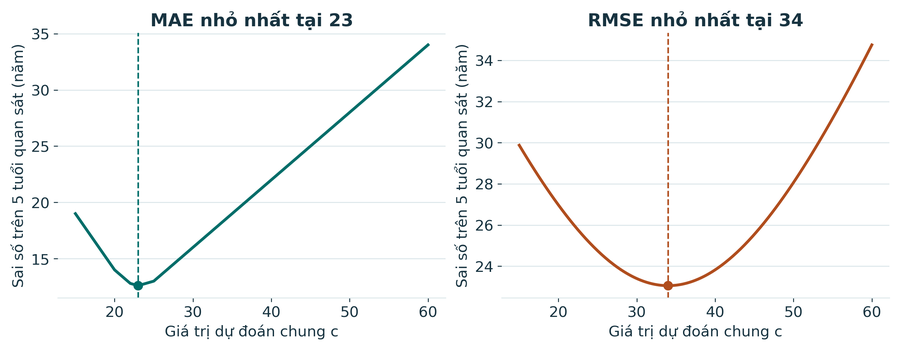

,candidate,MAE,RMSE
32,23.0,12.6,25.546
76,34.0,18.4,23.056


In [2]:
figure("constant_prediction_loss")
age_curve = pd.DataFrame(evidence["support"]["age_loss_curve"])
display(age_curve.loc[age_curve.candidate.isin([23, 34])].round(3))

Hai đường trên chấm dự đoán hằng số với năm tuổi đã quan sát. Tuổi thật ở NaN vẫn chưa biết.

## 1. Thiếu dữ liệu và phân tích đơn biến

`NaN`, `None` hoặc `pd.NA` biểu thị thiếu trong các kiểu dữ liệu khác nhau. Tài liệu miền quyết định chuỗi rỗng, `?`, `-999` có cần chuẩn hóa hay không. Giá trị 0 có thể là quan sát hợp lệ. Thiếu có thể đến từ bỏ trống câu hỏi, thiết bị lỗi, nhập liệu hoặc câu hỏi không áp dụng. Tính tỷ lệ thiếu cột $j$ bằng $m_j/N$. Nhiều phép tóm tắt bỏ qua NaN, từ đó có thể làm lệch mẫu dùng để suy luận.

Các biến được chọn gồm `G1` (điểm kỳ đầu), `absences` (số buổi vắng), `G3` (điểm cuối kỳ) và `guardian` (người giám hộ). Giữ `school` quan sát đầy đủ. Che Bernoulli độc lập với giá trị (MCAR). Với MAR, xác suất thiếu có thể phụ thuộc phần quan sát. Với MNAR, phần chưa quan sát vẫn ảnh hưởng sau khi xét phần quan sát. Biểu đồ và tỷ lệ thiếu chỉ cung cấp dấu hiệu để đặt câu hỏi về cơ chế.

,số ô thiếu,tỷ lệ thiếu
G1,113,17.41%
absences,94,14.48%
G3,97,14.95%
guardian,94,14.48%
school,0,0.00%


,count,mean,median,mode,std,min,max,skewness,q1,q3,iqr,upper_fence,iqr_flag_count
variable,,,,,,,,,,,,,
G1,536.0,11.349,11.0,10,2.720,0.0,19.0,0.012,10.0,13.0,3.0,17.5,14.0
absences,555.0,3.706,2.0,0,4.664,0.0,32.0,2.082,0.0,6.0,6.0,15.0,18.0
G3,552.0,11.846,12.0,11,3.311,0.0,19.0,-1.003,10.0,14.0,4.0,20.0,16.0


,tần suất
guardian,
mother,390
father,134
other,31


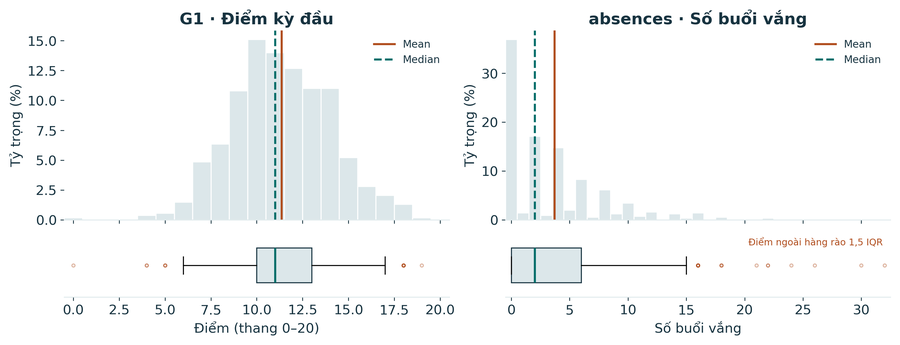

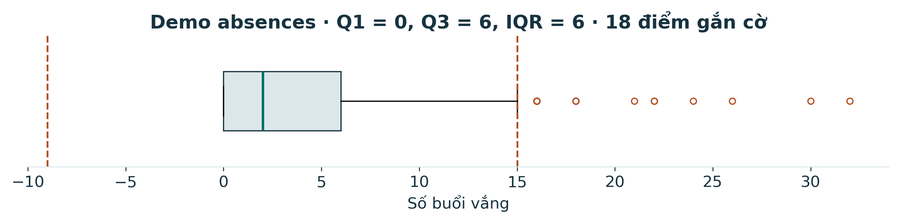

In [3]:
missing = pd.DataFrame({"số ô thiếu": observed.isna().sum(), "tỷ lệ thiếu": observed.isna().mean()})
display(missing.style.format({"tỷ lệ thiếu": "{:.2%}"}))
eda = pd.DataFrame(evidence["eda"]).set_index("variable")
display(eda[["count", "mean", "median", "mode", "std", "min", "max", "skewness", "q1", "q3", "iqr", "upper_fence", "iqr_flag_count"]].round(3))
display(observed[CATEGORY].value_counts().rename("tần suất").to_frame())
figure("eda_numeric")
figure("iqr_outliers")

Đọc histogram và boxplot cùng nhau. G1 gần đối xứng ở vùng trung tâm và Mean khá gần Median, song vẫn có điểm ngoài hàng rào 1,5 IQR. Với số buổi vắng, đuôi kéo sang phải, Mean cao hơn Median. Hàng rào 1,5 IQR gắn cờ để xem xét. Số buổi vắng bằng 0 là quan sát hợp lệ. Histogram dùng khoảng theo đơn vị nguyên để giữ đặc điểm rời rạc của điểm và số buổi vắng.

## 2. Chọn thống kê thay thế theo kiểu biến và mục tiêu

- **Mean** $\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$ dùng mọi độ lớn quan sát. Khi một quan sát đổi thêm $\Delta$, Mean đổi $\Delta/n$.
- **Median** là vị trí giữa sau khi sắp xếp. Với $n$ chẵn lấy trung bình hai vị trí giữa. Thứ hạng giúp Median bền hơn trước giá trị cực đoan.
- **Mode** là giá trị có tần suất cực đại. Với dữ liệu liên tục, đỉnh mật độ hoặc khoảng histogram có thể hữu ích hơn phép đếm trùng khớp. Nhiều giá trị có thể đồng hạng.

Ký hiệu đuôi điển hình là skewness dương cho đuôi phải và âm cho đuôi trái. Thứ tự trên hình là tính chất của các phân phối minh họa cụ thể. Đối xứng còn có thể gặp ở tam giác và hỗn hợp hai cụm. Xem thêm [NIST về skewness](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm).

| Bằng chứng quan sát | Phương pháp nên thử | Vì sao và cần kiểm chứng gì |
|---|---|---|
| Định lượng gần đối xứng, ít ngoại lệ | Mean | Dùng độ lớn của mọi quan sát. Kiểm tra miền giá trị và RMSE. |
| Định lượng lệch hoặc nhiều điểm cực đoan | Median | Bền theo thứ hạng. Kiểm tra MAE, RMSE và đỉnh nhân tạo. |
| Định tính | Mode | Nhãn phổ biến nhất. Kiểm tra đa Mode và lớp hiếm. |
| Nhóm quan sát được, phân phối khác nhau | Thống kê theo nhóm | Giữ sự khác biệt có ý nghĩa. Kiểm tra nhóm hiếm, cột nhóm và leakage. |
| Nhiều đỉnh hoặc đồng hạng Mode | Phân tích cấu trúc trước | Cân nhắc thống kê có điều kiện và công bố quy tắc hòa. |

Đây là các điểm bắt đầu. Chọn theo ngữ nghĩa, biểu đồ, mức độ thiếu và mục tiêu, thay vì đặt ngưỡng skewness hoặc tỷ lệ thiếu chung.

Age: Mean = 34, Median = 23.
Size: Mode = ['M'].
Đa Mode: [2, 8], Mean = 4.6, Median = 3.


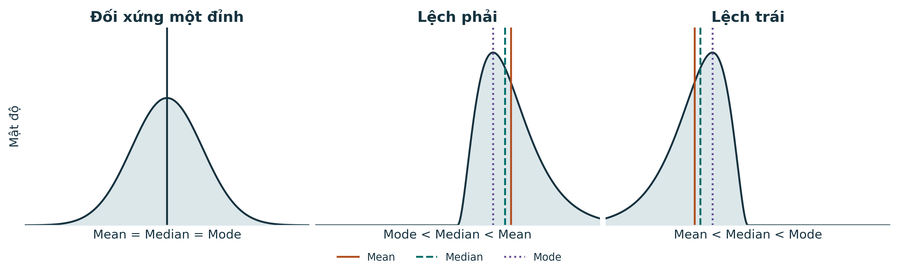

In [4]:
figure("distribution_theory")
age = pd.Series([20, 22, 23, 25, 80, np.nan])
size = pd.Series(["M", "M", "L", "S", np.nan, "M"])
tie = pd.Series([2, 2, 3, 8, 8, np.nan])
print(f"Age: Mean = {age.mean():g}, Median = {age.median():g}.")
print(f"Size: Mode = {size.mode().tolist()}.")
print(f"Đa Mode: {tie.mode().astype(int).tolist()}, Mean = {tie.mean():g}, Median = {tie.median():g}.")

Tuổi 80 cao so với cụm 20–25 trong mẫu nhỏ này và có thể là quan sát hợp lệ. Nếu muốn một giá trị thay thế gần cụm, 23 là một lựa chọn minh họa. Tuổi thật bị che vẫn chưa biết. Size là nhãn, nên phép cộng mã số sẽ phụ thuộc cách mã hóa. Ví dụ đa Mode có hai mốt. `most_frequent` chọn giá trị nhỏ nhất khi hòa, là một quy tắc ổn định cần công bố. [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)

## 3. Điền bằng SimpleImputer trong demo EDA

Fit từ phần quan sát của chính bảng để xem điều gì thay đổi trong bảng. Phần minh họa này phục vụ so sánh phân phối.

Mean: điền 3.706306306306306, sau điền còn 0 ô thiếu.
Median: điền 2.0, sau điền còn 0 ô thiếu.
Mode: điền mother, sau điền còn 0 ô thiếu.


,stage,count,mean,median,std,variance,missing_rate
1,Complete,649,3.6595,2.0000,4.6408,21.5366,0.0000
4,Observed,555,3.7063,2.0000,4.6636,21.7493,0.1448
7,Mean,649,3.7063,3.7063,4.3121,18.5943,0.0000
10,Median,649,3.4592,2.0000,4.3538,18.9555,0.0000


stage,Complete,Mode,Observed
category,,,
father,153,134,134
mother,455,484,390
other,41,31,31


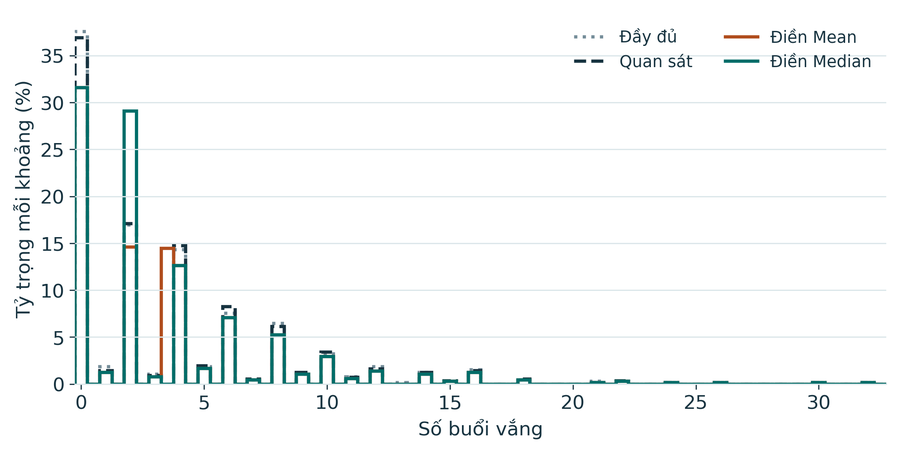

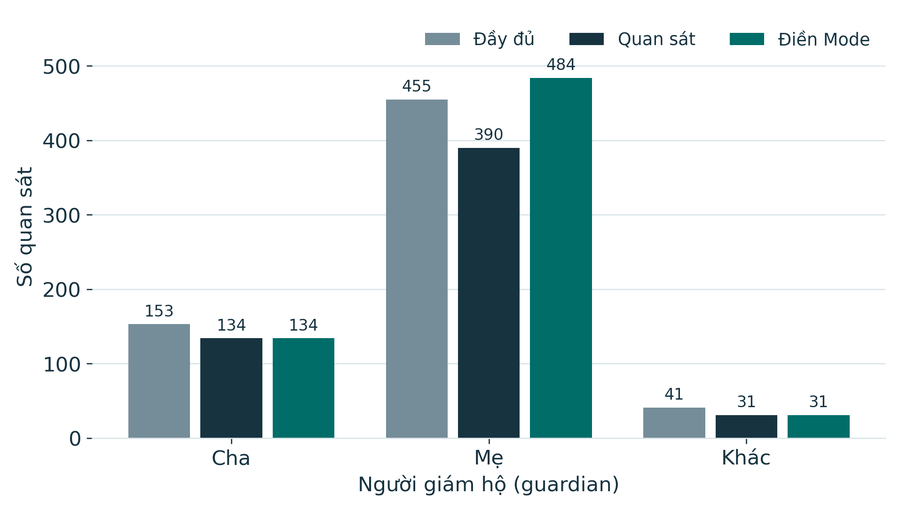

In [5]:
mean_imputer = SimpleImputer(strategy="mean")
median_imputer = SimpleImputer(strategy="median")
mode_imputer = SimpleImputer(strategy="most_frequent")
skew = NUMERIC[1]
for label, imputer, variable in [
    ("Mean", mean_imputer, skew), ("Median", median_imputer, skew), ("Mode", mode_imputer, CATEGORY),
]:
    result = imputer.fit_transform(observed[[variable]])
    print(f"{label}: điền {imputer.statistics_[0]}, sau điền còn {pd.isna(result).sum()} ô thiếu.")

stages, distribution, category_frequencies = describe_demo(complete, observed)
display(distribution.query("variable == @skew").drop(columns=["variable", "corr_school_GP"]).round(4))
display(category_frequencies.pivot(index="category", columns="stage", values="count"))
figure("numeric_imputation_before_after")
figure("categorical_mode")

Mean giữ Mean quan sát trong demo vì mọi ô điền có độ lệch bằng 0 so với Mean đó. Với $n$ ô quan sát và $m$ ô điền, phương sai mẫu trở thành $s^2_{\rm obs}(n-1)/(n+m-1)$ khi $n\ge2$. Công thức này so sánh với phần quan sát đã dùng để tính Mean. Mean từ train có thể khác Mean quan sát của test. Giá trị Mean lẻ của số buổi vắng được giữ để chấm dự đoán điểm. Nếu đầu ra phải là số đếm, hãy kiểm thử riêng quy tắc làm tròn. Median và Mode làm tăng tần suất tại giá trị điền. Điền hằng số toàn cục có thể làm suy yếu liên hệ với trường.

## 4. Benchmark trên ô test bị che

1. Chia 75/25 theo hàng từ dữ liệu đầy đủ.
2. Với mỗi mức 5%, 15%, 30%, tạo 12 bộ mặt nạ train và test từ hai luồng RNG độc lập. Mỗi cặp phương pháp dùng cùng mặt nạ.
3. Fit trên train đã che rồi transform test đã che. Chỉ lấy ground truth ở ô test có mask True.
4. Với $k$ ô test che và $e_i=\hat{x}_i-x_i$, MAE là $\sum|e_i|/k$, RMSE là $\sqrt{\sum e_i^2/k}$. Với nhãn, Accuracy là số khớp chia cho $k$.

SD đi kèm điểm trung bình đo sự dao động theo mặt nạ, trên cùng lần chia. Sai số điểm thấp không bảo đảm bảo toàn hình dạng hoặc liên hệ giữa các biến. [scikit-learn về data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

metric                                     Accuracy          MAE         RMSE
variable method                                                              
G1       Mean                                     —  2.41 ± 0.36  2.99 ± 0.44
         Median                                   —  2.44 ± 0.35  3.07 ± 0.44
G3       Group Median                             —  2.35 ± 0.31  3.19 ± 0.52
         Mean                                     —  2.43 ± 0.25  3.19 ± 0.47
         Median                                   —  2.42 ± 0.25  3.17 ± 0.48
absences Mean                                     —  2.83 ± 0.36  3.69 ± 0.81
         Median                                   —  2.52 ± 0.47  3.86 ± 0.93
guardian Mode          68.87% ± 6.54 điểm phần trăm            —            —

missing_rate                     0.05   0.15   0.30
variable method       metric                       
G1       Mean         MAE       2.444  2.407  2.481
                      RMSE      2.955  2.987  3.073
         Median       MAE       2.494  2.438  2.501
                      RMSE      3.034  3.067  3.133
G3       Group Median MAE       2.024  2.348  2.405
                      RMSE      2.799  3.193  3.295
         Mean         MAE       2.388  2.433  2.507
                      RMSE      2.953  3.187  3.314
         Median       MAE       2.381  2.417  2.497
                      RMSE      2.933  3.167  3.306
absences Mean         MAE       2.539  2.832  2.956
                      RMSE      3.152  3.690  3.922
         Median       MAE       2.294  2.521  2.670
                      RMSE      3.077  3.856  4.095
guardian Mode         Accuracy  0.635  0.689  0.692

,variable,metric,mean_difference,std_difference,median_wins,mean_wins,ties
0,G1,MAE,0.0304,0.0508,3,9,0
1,G1,RMSE,0.0798,0.0315,0,12,0
2,absences,MAE,-0.3109,0.2516,10,1,1
3,absences,RMSE,0.1656,0.1734,1,11,0
4,G3,MAE,-0.0161,0.0392,8,3,1
5,G3,RMSE,-0.0206,0.0420,10,2,0


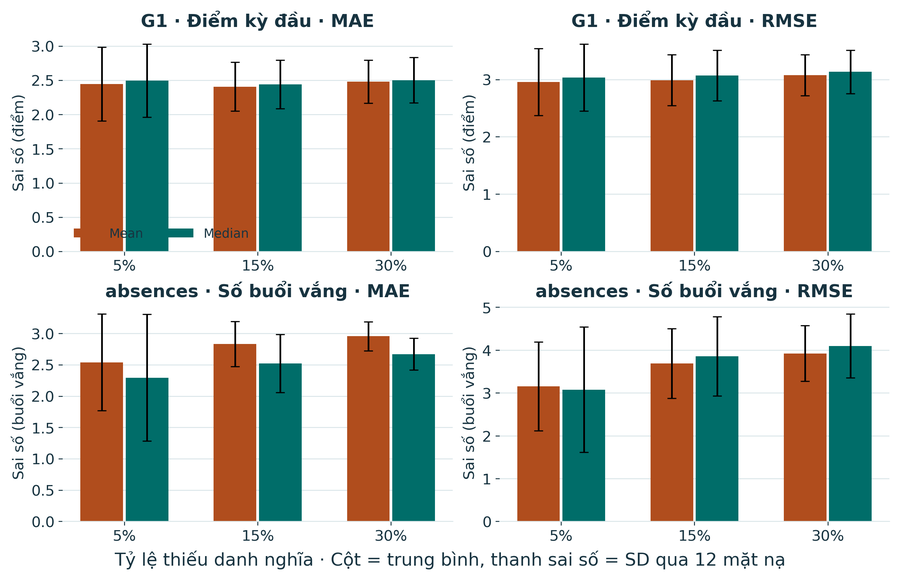

In [6]:
scores = pd.DataFrame(evidence["scores"])
focus = scores.loc[scores.missing_rate.eq(0.15)].copy()
focus["mean ± SD"] = focus.apply(
    lambda r: f"{r['mean']:.2%} ± {r['std'] * 100:.2f} điểm phần trăm" if r["metric"] == "Accuracy"
    else f"{r['mean']:.2f} ± {r['std']:.2f}", axis=1,
)
display(focus.pivot(index=["variable", "method"], columns="metric", values="mean ± SD").fillna("—"))
display(scores.pivot_table(index=["variable", "method", "metric"], columns="missing_rate", values="mean").round(3))
display(pd.DataFrame(evidence["support"]["paired"]).round(4))
figure("imputation_errors")

Với cùng một hằng số, tối thiểu hóa sai số tuyệt đối dẫn đến Median trên tập dùng để tối ưu. Tối thiểu hóa bình phương sai số dẫn đến Mean. Trên `absences` tại mức 15%, Median có MAE thấp hơn và Mean có RMSE thấp hơn. Hai lựa chọn cho điểm gần nhau trên `G1`. Accuracy khi điền mọi ô che bằng nhãn `mother` bằng tỷ lệ nhãn này trong các ô test bị che. Các nhãn `father` và `other` trong phần che bị điền sai.

## 5. Khác biệt theo trường và giới hạn

Điểm G3 ở GP và MS có phân phối chồng lấn, với Median toàn tập lần lượt là 13 và 11. Đồ thị dùng tỷ trọng trong mỗi trường vì số dòng giữa hai trường khác nhau. Nếu biết trường khi áp dụng, có thể học Median theo trường trên train. Nhóm chưa gặp hoặc dưới 20 quan sát dùng Median train toàn cục. Ở mức 15%, phương pháp theo trường có MAE thấp hơn một chút và RMSE tương tự. Chênh lệch điểm quan sát không xác lập tác động nhân quả của trường.

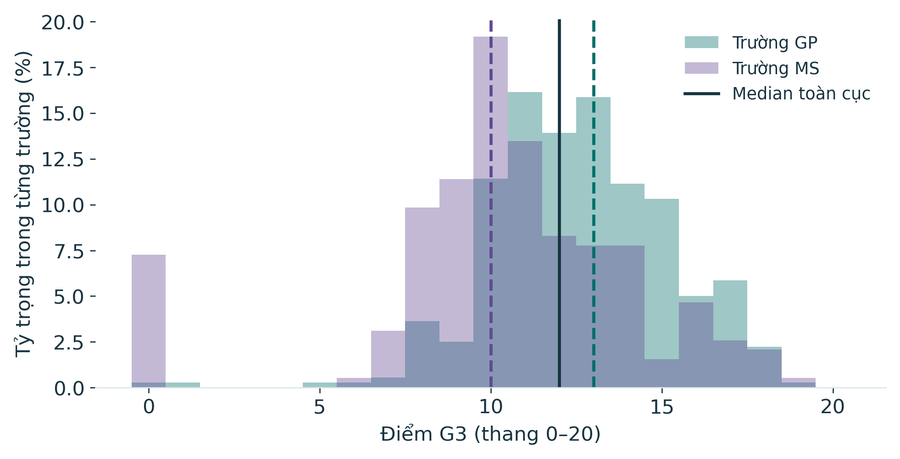

,school,size,median
0,GP,423,13.0
1,MS,226,11.0


,stage,mean,median,std,corr_school_GP
2,Complete,11.906,12.000,3.2307,0.2843
5,Observed,11.846,12.000,3.3108,0.3104
8,Mean,11.846,11.846,3.0530,0.2865
11,Median,11.869,12.000,3.0535,0.2866


,missing_rate,variable,method,metric,mean,std,repeats,mean_actual_test_rate,mean_test_masked
0,0.15,G3,Group Median,MAE,2.1972,0.1495,12,0.1625,25.8333
1,0.15,G3,Group Median,RMSE,2.6969,0.2747,12,0.1625,25.8333
2,0.15,G3,Mean,MAE,2.2186,0.2401,12,0.1625,25.8333
3,0.15,G3,Mean,RMSE,2.6825,0.2571,12,0.1625,25.8333
4,0.15,G3,Median,MAE,2.1926,0.2521,12,0.1625,25.8333
5,0.15,G3,Median,RMSE,2.6840,0.2548,12,0.1625,25.8333


complete        0.284294
observed        0.286059
mean_imputed    0.263642
Name: Tương quan G3–GP, TB 300 lần che 15%, dtype: float64

In [7]:
figure("g3_by_school")
multi = NUMERIC[2]
display(pd.DataFrame(evidence["schools"]))
display(distribution.loc[distribution.variable.eq(multi), ["stage", "mean", "median", "std", "corr_school_GP"]].round(4))
display(pd.DataFrame(evidence["support"]["zero_grade_sensitivity"]).round(4))
display(pd.Series(evidence["support"]["correlations"], name="Tương quan G3–GP, TB 300 lần che 15%"))

**Vì sao dùng được?** Thống kê trung tâm cho dự đoán chung tối ưu theo tổn thất đã chọn trên phân phối thích hợp.

**Khi nào hợp lý?** Phần quan sát đủ đại diện cho phần thiếu, kiểu biến và thông tin dùng để dự đoán phù hợp với mục tiêu. Thứ hạng trên test cần kiểm chứng.

**Sai lệch thế nào?** Các ô điền mất biến thiên, tần suất tăng tại giá trị thay thế và liên hệ giữa biến có thể thay đổi.

Bản gốc có 15 dòng G3 bằng 0, gồm 14 dòng MS, được giữ trong benchmark chính. Thử loại các dòng này trước khi chia lại là phân tích độ nhạy với một tập đối tượng khác.

Khi thiếu có hệ thống hoặc cần suy luận bất định, hãy khảo sát độ nhạy và cân nhắc phương pháp có điều kiện hoặc multiple imputation. Benchmark này giới hạn ở mẫu môn tiếng Bồ Đào Nha và các mặt nạ MCAR đã mô tả.

## 6. Điền khuyết ảnh hưởng mô hình dự đoán G3 thế nào?

Giữ G3 đầy đủ làm đích; X gồm G1, G2, age, absences, guardian, school. Bối cảnh sau khi G1/G2 có sẵn. Pipeline học từ train. So Mean/Median/Mode cho biến số, giữ Mode cho biến loại. 5 split × 4 mask × 3 mức × 3 cách điền × 2 mô hình + 10 mốc đầy đủ = 370 pipeline.

Các metric chấm **mọi dòng test** bằng G3 thật. Hai pha test dùng cùng pipeline đã fit. Mốc đầy đủ dùng cùng split. SD mô tả dao động với các test chồng lấn; không phải CI. Siêu tham số cố định trước.

Đầu vào: ['G1', 'G2', 'age', 'absences', 'guardian', 'school'] | G3 luôn đầy đủ


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['G1', 'G2', 'age',
                                                   'absences']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ign

metric,MAE,R2,RMSE
model,,,
Predict train mean,2.431,-0.005,3.324
Random Forest,0.810,0.832,1.359
Ridge,0.829,0.827,1.379


metric                          MAE             R2           RMSE
model         method                                             
Random Forest Mean    0.973 ± 0.098  0.760 ± 0.060  1.614 ± 0.201
              Median  1.001 ± 0.094  0.752 ± 0.064  1.640 ± 0.209
              Mode    1.004 ± 0.086  0.750 ± 0.060  1.646 ± 0.195
Ridge         Mean    1.074 ± 0.104  0.725 ± 0.066  1.728 ± 0.229
              Median  1.078 ± 0.103  0.723 ± 0.064  1.734 ± 0.227
              Mode    1.087 ± 0.097  0.719 ± 0.061  1.748 ± 0.219

phase,"Masked train, clean test","Masked train, masked test"
model,,
Random Forest,1.431,1.640
Ridge,1.457,1.734


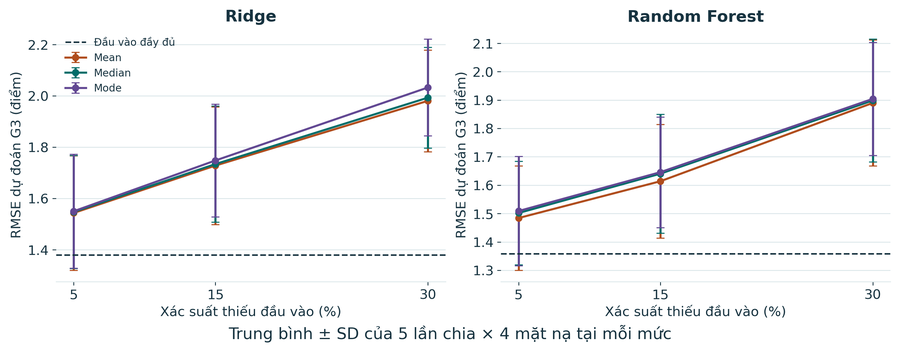

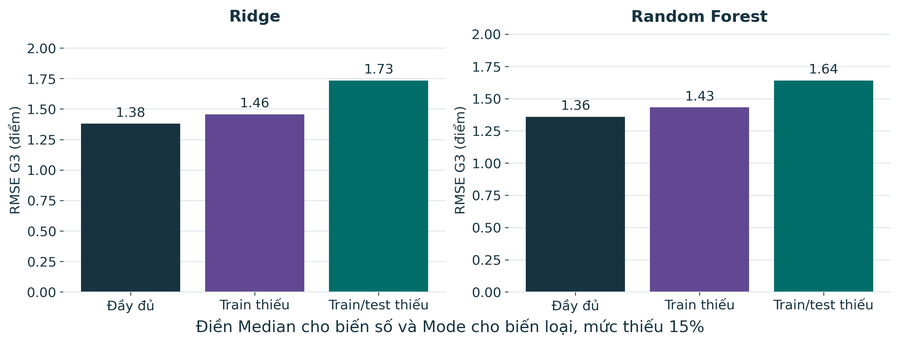

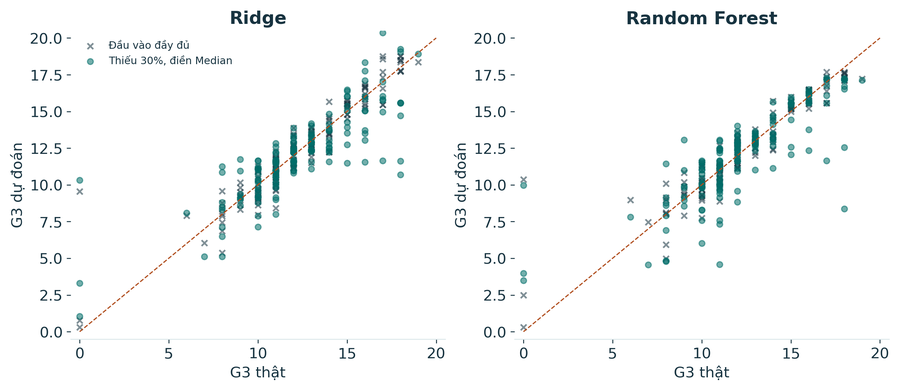

In [8]:
from src.run_model_experiments import load_model_data, build_pipeline

X_model, y_model = load_model_data(root)
assert "G3" not in X_model and not y_model.isna().any()
print("Đầu vào:", list(X_model.columns), "| G3 luôn đầy đủ")
display(build_pipeline("Median", "Ridge"))
model_evidence = evidence["models"]
assert model_evidence["fits"] == 370
model_scores = pd.DataFrame(model_evidence["evaluation"])
model_reference = pd.DataFrame(model_evidence["reference"])
selected = model_scores.loc[
    model_scores.missing_rate.eq(.15)
    & model_scores.phase.eq("Masked train, masked test")
    & model_scores.subset.eq("All test")
    & model_scores.metric.isin(["MAE", "RMSE", "R2"])
].copy()
selected["mean ± SD"] = selected.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)
display(model_reference.pivot(index="model", columns="metric", values="mean").round(3))
display(selected.pivot(index=["model", "method"], columns="metric", values="mean ± SD"))
phases = model_scores.loc[
    model_scores.missing_rate.eq(.15) & model_scores.method.eq("Median")
    & model_scores.subset.eq("All test") & model_scores.metric.eq("RMSE")
]
display(phases.pivot(index="model", columns="phase", values="mean").round(3))
figure("model_performance")
figure("model_train_test_effect")
figure("model_predictions")

Với thiếu 15% ở train và test, Ridge có RMSE từ 1,379 lên 1,728 với Mean, 1,734 với Median, 1,748 với Mode. Random Forest từ 1,359 lên 1,614, 1,640 và 1,646. Đây là trung bình RMSE từng lần chạy; bảng có SD, MAE, R².

Trong thiết kế này, mất thông tin đầu vào ảnh hưởng lớn hơn chênh giữa cách điền. Median tốt hơn theo MAE khôi phục absences không bảo đảm tốt nhất theo RMSE G3 của mô hình nhiều biến. Chưa xác lập ý nghĩa thống kê cho chênh nhỏ. Kết quả giới hạn ở dataset, biến, mô hình, cấu hình và MCAR công bố.

Từng dự đoán ở results/model_predictions.csv, từng split ở results/model_split_assignments.csv. Không điền G3 tạo nhãn giả và không dùng test để học thống kê.